In [395]:
import pandas as pd
from requests import head
import numpy as np

df_validation = pd.read_csv("outputs/VALIDATION_FD001.csv")
df_fitting = pd.read_csv("outputs/FITTING_FD001.csv")

df_fitting.head()

,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,23,24,25,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191.0
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190.0
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189.0
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188.0
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187.0


### Rolling average

In [396]:
# sort by id and cycle
fitting = df_fitting.copy().sort_values(by=["0", "1"])
validation = df_validation.copy().sort_values(by=["0", "1"])

# drop constant columns
counts = fitting.nunique()
constants = counts[counts == 1].index
print(constants)

fitting = fitting.drop(columns=constants)
validation = validation.drop(columns=constants)

print(fitting.head())




Index(['4', '5', '9', '14', '20', '22', '23'], dtype='str')
   0  1       2       3       6        7        8     10      11       12  \
0  1  1 -0.0007 -0.0004  641.82  1589.70  1400.60  21.61  554.36  2388.06   
1  1  2  0.0019 -0.0003  642.15  1591.82  1403.14  21.61  553.75  2388.04   
2  1  3 -0.0043  0.0003  642.35  1587.99  1404.20  21.61  554.26  2388.08   
3  1  4  0.0007  0.0000  642.35  1582.79  1401.87  21.61  554.45  2388.11   
4  1  5 -0.0019 -0.0002  642.37  1582.85  1406.22  21.61  554.00  2388.06   

        13     15      16       17       18      19   21     24       25  \
0  9046.19  47.47  521.66  2388.02  8138.62  8.4195  392  39.06  23.4190   
1  9044.07  47.49  522.28  2388.07  8131.49  8.4318  392  39.00  23.4236   
2  9052.94  47.27  522.42  2388.03  8133.23  8.4178  390  38.95  23.3442   
3  9049.48  47.13  522.86  2388.08  8133.83  8.3682  392  38.88  23.3739   
4  9055.15  47.28  522.19  2388.04  8133.80  8.4294  393  38.90  23.4044   

     RUL  
0  191.0 

In [397]:
def rolling_average(data_frame, col, window_size):

    def apply_rolling_average(data):
            return data.rolling(window=window_size).mean()
    
    grouped_col = data_frame.groupby("0")
    selected_col = grouped_col[col]
    
    new_feature = selected_col.transform(apply_rolling_average)
    data_frame[f"{col}_mean_{window_size}"] = new_feature

    return data_frame

In [398]:
fitting_rolling_avrg = fitting
validation_rolling_avrg = validation

for i in range(2, 26):
    if str(i) in constants:
        continue
    for j in [10, 20]:
        fitting_rolling_avrg = rolling_average(fitting_rolling_avrg, f"{i}", j)
        validation_rolling_avrg = rolling_average(validation_rolling_avrg, f"{i}", j)

print(fitting_rolling_avrg.head())

   0  1       2       3       6        7        8     10      11       12  \
0  1  1 -0.0007 -0.0004  641.82  1589.70  1400.60  21.61  554.36  2388.06   
1  1  2  0.0019 -0.0003  642.15  1591.82  1403.14  21.61  553.75  2388.04   
2  1  3 -0.0043  0.0003  642.35  1587.99  1404.20  21.61  554.26  2388.08   
3  1  4  0.0007  0.0000  642.35  1582.79  1401.87  21.61  554.45  2388.11   
4  1  5 -0.0019 -0.0002  642.37  1582.85  1406.22  21.61  554.00  2388.06   

   ...  18_mean_10  18_mean_20  19_mean_10  19_mean_20  21_mean_10  \
0  ...         NaN         NaN         NaN         NaN         NaN   
1  ...         NaN         NaN         NaN         NaN         NaN   
2  ...         NaN         NaN         NaN         NaN         NaN   
3  ...         NaN         NaN         NaN         NaN         NaN   
4  ...         NaN         NaN         NaN         NaN         NaN   

   21_mean_20  24_mean_10  24_mean_20  25_mean_10  25_mean_20  
0         NaN         NaN         NaN         NaN   

In [399]:
fitting_rolling_avrg = fitting_rolling_avrg.dropna()
validation_rolling_avrg = validation_rolling_avrg.dropna()

# for comparison with the later used rolling mean + slope features, we need to remove everything till row 40:
fitting_rolling_avrg_cropped = fitting_rolling_avrg.loc[fitting_rolling_avrg["1"] >= 40]
validation_rolling_avrg_cropped = validation_rolling_avrg.loc[validation_rolling_avrg["1"] >= 40]

print(fitting_rolling_avrg_cropped.head())

    0   1       2       3       6        7        8     10      11       12  \
39  1  40 -0.0000 -0.0004  642.24  1582.08  1401.77  21.61  554.57  2388.06   
40  1  41  0.0033  0.0004  642.40  1591.31  1403.21  21.61  553.72  2388.06   
41  1  42  0.0005 -0.0004  642.12  1584.66  1401.38  21.61  553.94  2388.08   
42  1  43 -0.0027  0.0005  642.24  1591.52  1406.05  21.61  553.68  2388.03   
43  1  44 -0.0001  0.0002  641.93  1586.94  1401.20  21.61  554.15  2388.04   

    ...  18_mean_10  18_mean_20  19_mean_10  19_mean_20  21_mean_10  \
39  ...    8132.006   8132.3425     8.41254    8.411340       391.9   
40  ...    8133.286   8132.5455     8.41520    8.412945       391.9   
41  ...    8133.404   8132.5690     8.41509    8.413460       391.9   
42  ...    8132.684   8132.5350     8.41824    8.412600       391.9   
43  ...    8133.168   8132.4135     8.41676    8.414150       391.9   

    21_mean_20  24_mean_10  24_mean_20  25_mean_10  25_mean_20  
39       392.0      38.918     38

First Test to see wether that improved model performance:

In [400]:
fitting_X = fitting_rolling_avrg_cropped.drop(columns=["RUL", "0"])
fitting_Y = fitting_rolling_avrg_cropped["RUL"]

validation_X = validation_rolling_avrg_cropped.drop(columns=["RUL", "0"])
validation_Y = validation_rolling_avrg_cropped["RUL"]


from sklearn.neighbors import KNeighborsRegressor
from sklearn import preprocessing

scaler = preprocessing.StandardScaler()

scaler.fit(fitting_X)
scaled_fitting_X = scaler.transform(fitting_X)
scaled_validation_X = scaler.transform(validation_X)

knn_model_scaled = KNeighborsRegressor(n_neighbors=40)

knn_model_scaled.fit(scaled_fitting_X, fitting_Y)
knn_predictions = knn_model_scaled.predict(scaled_validation_X)

knn_error = knn_predictions - validation_Y 

mae = np.abs(knn_error).mean()
print(mae)

rmse = np.sqrt((knn_error ** 2).mean())
print(rmse)

mean_signed_error = knn_error.mean()
print(mean_signed_error)

26.298343518816342
34.30794419633874
12.660550016082341


if we compare those results with the results in notebook 5 - We have to realize that the performance didnt increase much! - My learning: Not all additional features really add value to our prediction performance. So I will aproach this a bit more structured and precisely select which features to add to my data. Next i want to jsut visualise some sensors and the effect different rolling averages have on it

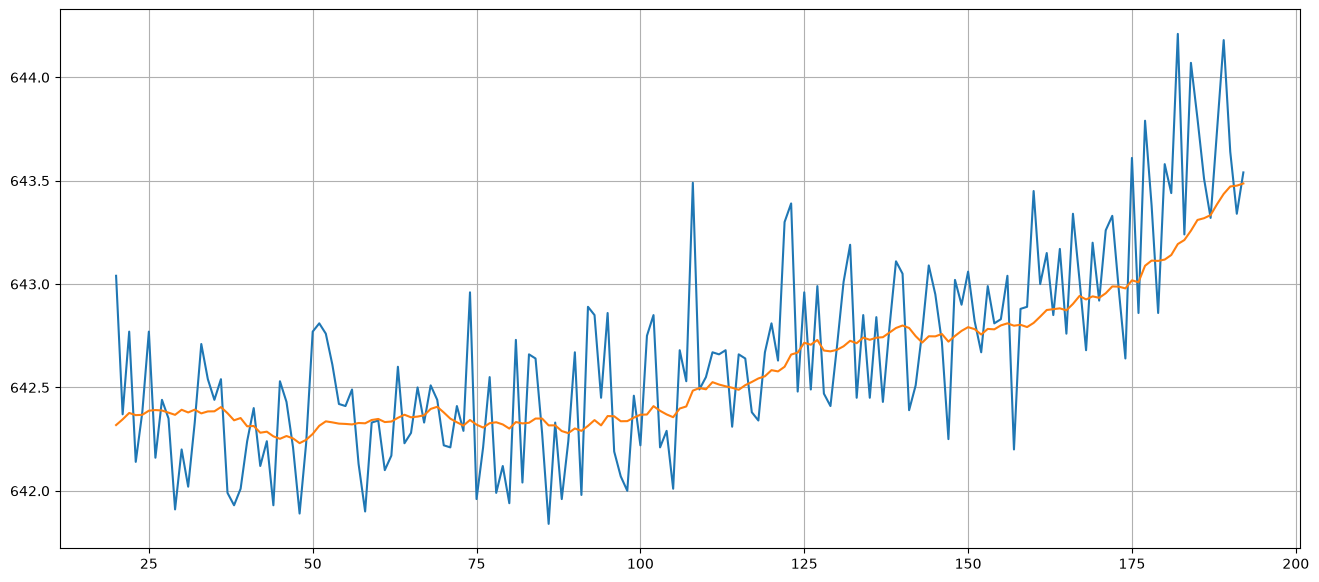

In [401]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16,7))
plt.grid(True)

engine1 = fitting_rolling_avrg.loc[fitting_rolling_avrg["0"] == 1]

plt.plot(engine1["1"], engine1["6"])
#plt.plot(engine1["1"], engine1["6_mean_10"])
plt.plot(engine1["1"], engine1["6_mean_20"])


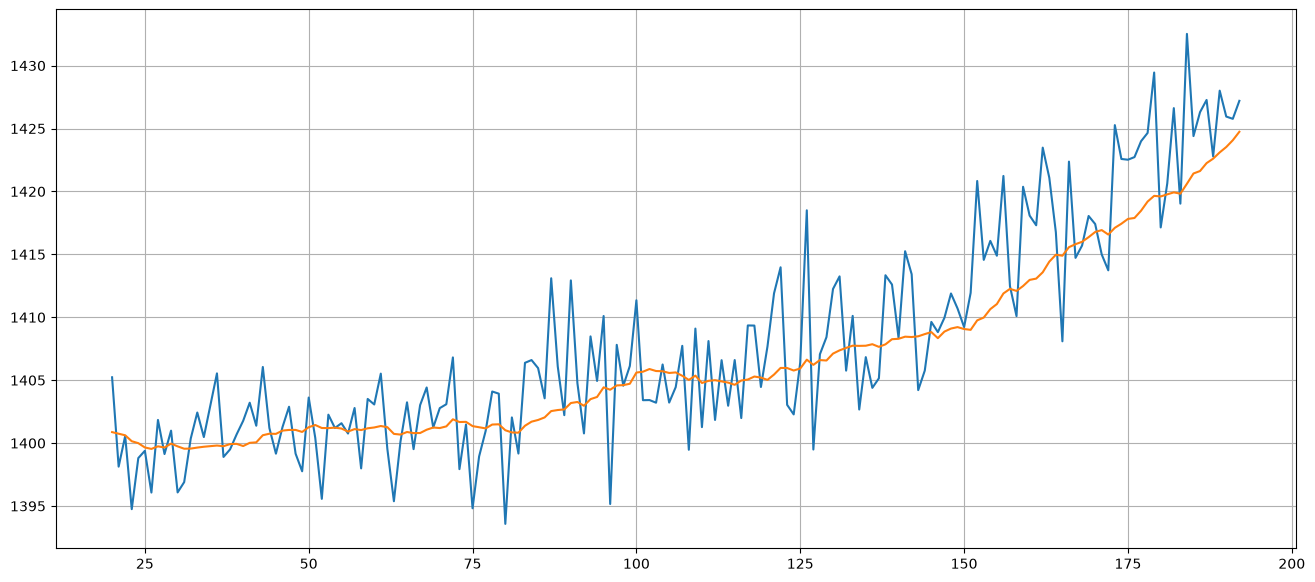

In [402]:
plt.figure(figsize=(16,7))
plt.grid(True)

plt.plot(engine1["1"], engine1["8"])
#plt.plot(engine1["1"], engine1["8_mean_10"])
plt.plot(engine1["1"], engine1["8_mean_20"])

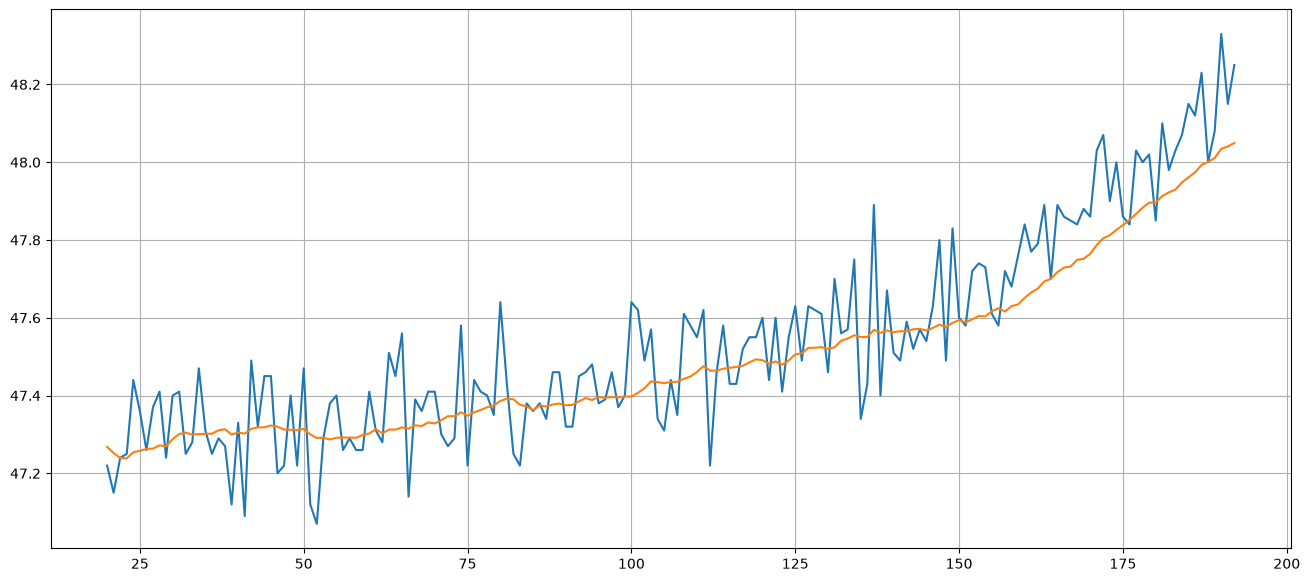

In [403]:
plt.figure(figsize=(16,7))
plt.grid(True)

plt.plot(engine1["1"], engine1["15"])
#plt.plot(engine1["1"], engine1["15_mean_10"])
plt.plot(engine1["1"], engine1["15_mean_20"])


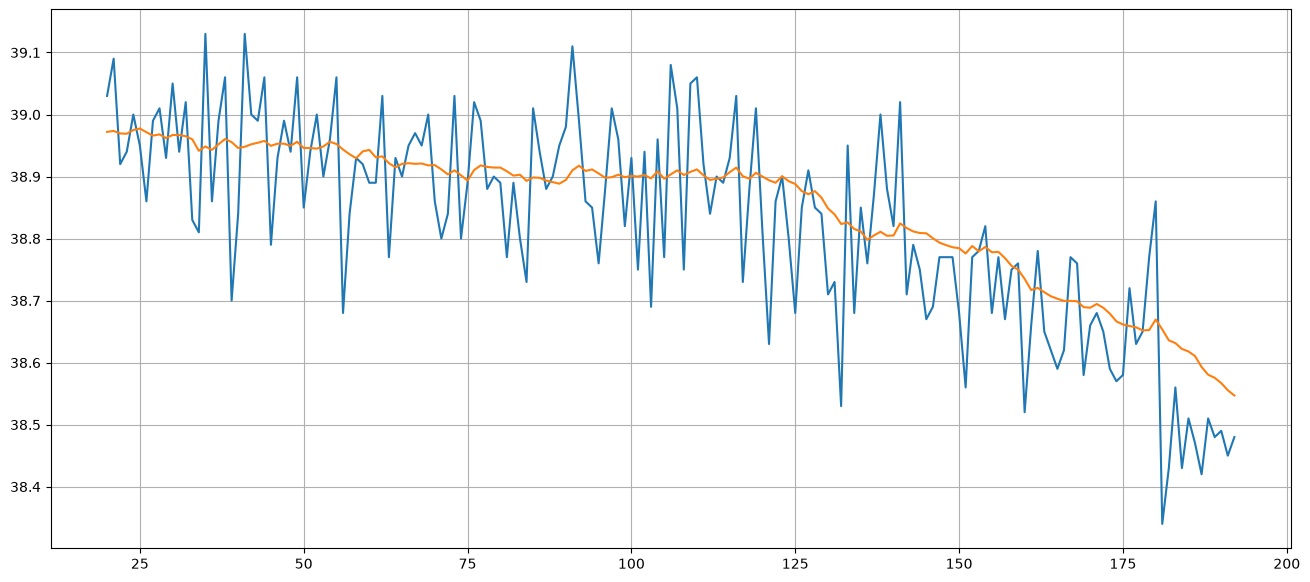

In [404]:
plt.figure(figsize=(16,7))
plt.grid(True)

plt.plot(engine1["1"], engine1["24"])
#plt.plot(engine1["1"], engine1["24_mean_10"])
plt.plot(engine1["1"], engine1["24_mean_20"])


Now my idea would be that ON the rolling average (window 20) we could add a feature determining the slope, because the slope really increases (in absolute value):

### Difference based slope:

In [405]:
def slope(data_frame, col):

    def apply_slope(data):
        return data.diff(periods=20) / 20
    
    grouped_col = data_frame.groupby("0")
    selected_col = grouped_col[col]
    
    new_feature = selected_col.transform(apply_slope)
    data_frame[f"{col}_slope"] = new_feature

    return data_frame

for i in range(2, 26):
    if str(i) in constants:
        continue
    fitting = slope(fitting_rolling_avrg, f"{i}_mean_20")
    validation = slope(validation_rolling_avrg, f"{i}_mean_20")

fitting = fitting.dropna()
validation = validation.dropna()

# this was added in the end because i decided this was a good first improvement via feature engineering and we are gonna use this data for upcoming models
fitting.to_csv("outputs/FITTING_FD001_FEATURED.csv", index=False)
validation.to_csv("outputs/VALIDATION_FD001_FEATURED.csv", index=False)

print(fitting.head())

    0   1       2       3       6        7        8     10      11       12  \
39  1  40 -0.0000 -0.0004  642.24  1582.08  1401.77  21.61  554.57  2388.06   
40  1  41  0.0033  0.0004  642.40  1591.31  1403.21  21.61  553.72  2388.06   
41  1  42  0.0005 -0.0004  642.12  1584.66  1401.38  21.61  553.94  2388.08   
42  1  43 -0.0027  0.0005  642.24  1591.52  1406.05  21.61  553.68  2388.03   
43  1  44 -0.0001  0.0002  641.93  1586.94  1401.20  21.61  554.15  2388.04   

    ...  12_mean_20_slope  13_mean_20_slope  15_mean_20_slope  \
39  ...         -0.000150          0.022450          0.001850   
40  ...         -0.000400          0.019650          0.002500   
41  ...         -0.000300         -0.033575          0.003750   
42  ...         -0.000275          0.012075          0.003975   
43  ...         -0.000500          0.034150          0.003225   

    16_mean_20_slope  17_mean_20_slope  18_mean_20_slope  19_mean_20_slope  \
39          0.006575          0.000525         -0.013250

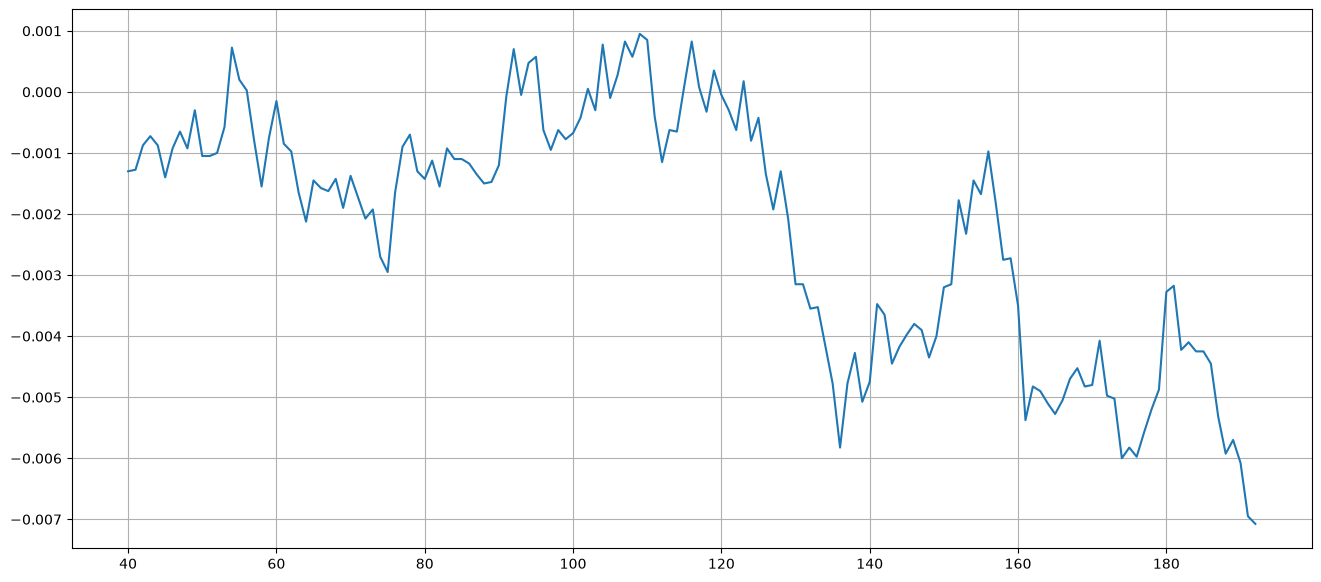

In [406]:
plt.figure(figsize=(16,7))
plt.grid(True)

engine1 = fitting.loc[fitting["0"] == 1]
plt.plot(engine1["1"], engine1["24_mean_20_slope"])

In [407]:
fitting_X = fitting.drop(columns=["RUL", "0"])
fitting_Y = fitting["RUL"]

validation_X = validation.drop(columns=["RUL", "0"])
validation_Y = validation["RUL"]

scaler = preprocessing.StandardScaler()

scaler.fit(fitting_X)
scaled_fitting_X = scaler.transform(fitting_X)
scaled_validation_X = scaler.transform(validation_X)

knn_model_scaled = KNeighborsRegressor(n_neighbors=40)

knn_model_scaled.fit(scaled_fitting_X, fitting_Y)
knn_predictions = knn_model_scaled.predict(scaled_validation_X)

knn_error = knn_predictions - validation_Y 

mae = np.abs(knn_error).mean()
print(mae)

rmse = np.sqrt((knn_error ** 2).mean())
print(rmse)

mean_signed_error = knn_error.mean()
print(mean_signed_error)

21.64794146027662
30.287341183141734
11.042328723062077


the above shown numbers are testing the set which each cycle starting in row 40 since i removed 20 for the rolling mean with windowsize 20, and ANOTHER 20. To make for a fair comparison with the previous test where we used ONLY the rolling mean, we need to remove 20 more lines from that first set so both start at cycle 40. 

Results and Comparison:

Standardized kNN (`k=40`), evaluated on validation cycles ≥ 40. MAE and RMSE are in cycles.

| Features | Validation MAE | Validation RMSE |
| --- | ---: | ---: |
| Original + rolling means | 26.30 | 34.31 |
| Original + rolling means + slopes | 21.65 | 30.29 |

So our newly added features defnietly added some value to our model!


### Lag

In [408]:
def lag(data_frame, col):

    def apply_lag(data):
        return data.shift(40)
    
    grouped_col = data_frame.groupby("0")
    selected_col = grouped_col[col]
    
    new_feature = selected_col.transform(apply_lag)

    return new_feature

fitting_with_lag = fitting.copy()
validation_with_lag = validation.copy()

for i in range(2, 26):
    if str(i) in constants:
        continue
    fitting_with_lag[f"{i}_lag_40"] = lag(df_fitting, f"{i}")
    validation_with_lag[f"{i}_lag_40"] = lag(df_validation, f"{i}")

fitting_with_lag = fitting_with_lag.dropna()
validation_with_lag = validation_with_lag.dropna()

print(fitting_with_lag.head())

    0   1       2       3       6        7        8     10      11       12  \
40  1  41  0.0033  0.0004  642.40  1591.31  1403.21  21.61  553.72  2388.06   
41  1  42  0.0005 -0.0004  642.12  1584.66  1401.38  21.61  553.94  2388.08   
42  1  43 -0.0027  0.0005  642.24  1591.52  1406.05  21.61  553.68  2388.03   
43  1  44 -0.0001  0.0002  641.93  1586.94  1401.20  21.61  554.15  2388.04   
44  1  45 -0.0013 -0.0000  642.53  1582.42  1399.16  21.61  553.83  2388.08   

    ...  12_lag_40  13_lag_40  15_lag_40  16_lag_40  17_lag_40  18_lag_40  \
40  ...    2388.06    9046.19      47.47     521.66    2388.02    8138.62   
41  ...    2388.04    9044.07      47.49     522.28    2388.07    8131.49   
42  ...    2388.08    9052.94      47.27     522.42    2388.03    8133.23   
43  ...    2388.11    9049.48      47.13     522.86    2388.08    8133.83   
44  ...    2388.06    9055.15      47.28     522.19    2388.04    8133.80   

    19_lag_40  21_lag_40  24_lag_40  25_lag_40  
40     8.4195

In [409]:
# And another time running the regressor

fitting_X = fitting_with_lag.drop(columns=["RUL", "0"])
fitting_Y = fitting_with_lag["RUL"]

validation_X = validation_with_lag.drop(columns=["RUL", "0"])
validation_Y = validation_with_lag["RUL"]


scaler = preprocessing.StandardScaler()

scaler.fit(fitting_X)
scaled_fitting_X = scaler.transform(fitting_X)
scaled_validation_X = scaler.transform(validation_X)

knn_model_scaled = KNeighborsRegressor(n_neighbors=40)

knn_model_scaled.fit(scaled_fitting_X, fitting_Y)
knn_predictions = knn_model_scaled.predict(scaled_validation_X)

knn_error = knn_predictions - validation_Y 

mae = np.abs(knn_error).mean()
print(mae)

rmse = np.sqrt((knn_error ** 2).mean())
print(rmse)

mean_signed_error = knn_error.mean()
print(mean_signed_error)

21.70924247329233
30.03239044029684
10.972661055357722


As we can see the lag doesnt really add any value :O .
Therefore i decide to save the fitting and validation sets which contain only the mean and slope, to be used in upcoming more powerful models!